# Experiment 9: Effect of PCA on Regression and Classification Models

## Aim
To study the impact of Principal Component Analysis (PCA) on machine learning model performance by comparing models trained in the original feature space (Without PCA) versus reduced feature space (With PCA) using 5-fold cross-validation across regression and classification tasks.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVC
from sklearn.model_selection import KFold, StratifiedKFold, cross_validate

In [2]:
data_path = 'data/pca_dataset.csv' if os.path.exists('data/pca_dataset.csv') else 'pca_dataset.csv'
df = pd.read_csv(data_path)
df.head()

,Math_Test1,Math_Test2,Math_Test3,Math_Assignment,Math_Attendance,Physics_Test1,Physics_Test2,Physics_Test3,Physics_Assignment,Physics_Attendance,...,Commute_Time_Min,Family_Income_Lakhs,Siblings,Hostel_Distance_Km,Club_Memberships,Age,Internet_Access,Study_Method,Final_Score,Performance_Level
0,55.0,74.3,68.4,80.6,82.3,55.2,53.1,66.2,67.2,61.2,...,35.0,2.40,1,3.38,2,19,Yes,Self,43.62,Average
1,47.3,58.4,58.6,63.3,73.8,52.9,54.3,53.9,65.1,70.5,...,34.0,3.79,0,2.51,0,20,Yes,Self,25.06,Poor
2,47.3,62.3,63.7,65.0,80.2,61.5,66.2,71.0,66.0,83.6,...,33.0,8.07,0,3.86,0,22,Yes,Group,39.45,Poor
3,60.5,67.1,68.1,80.6,86.9,61.4,60.6,68.0,77.4,95.4,...,48.0,5.72,1,2.76,0,20,Yes,Self,57.44,Good
4,48.2,49.4,48.6,58.0,61.7,54.1,41.4,51.0,57.6,67.5,...,45.0,NaN,0,3.76,1,19,Yes,Group,22.11,Poor


In [3]:
n_samples = df.shape[0]
n_features = df.shape[1] - 2
feature_names = [col for col in df.columns if col not in ['Final_Score', 'Performance_Level']]
missing_series = df.isnull().sum()
missing_features = missing_series[missing_series > 0]

print(f"Number of samples: {n_samples}")
print(f"Number of features: {n_features}")
print(f"Feature names (first 10 of {len(feature_names)}): {feature_names[:10]}")
print("\nRegression Target ('Final_Score') summary:")
print(df['Final_Score'].describe())
print("\nClassification Target ('Performance_Level') distribution:")
print(df['Performance_Level'].value_counts())
print("\nMissing values per column:")
print(missing_features)

Number of samples: 420
Number of features: 61
Feature names (first 10 of 61): ['Math_Test1', 'Math_Test2', 'Math_Test3', 'Math_Assignment', 'Math_Attendance', 'Physics_Test1', 'Physics_Test2', 'Physics_Test3', 'Physics_Assignment', 'Physics_Attendance']

Regression Target ('Final_Score') summary:
count    420.000000
mean      52.293476
std       13.257525
min        8.000000
25%       43.607500
50%       52.710000
75%       60.260000
max       93.000000
Name: Final_Score, dtype: float64

Classification Target ('Performance_Level') distribution:
Performance_Level
Average      126
Good         113
Poor         105
Excellent     76
Name: count, dtype: int64

Missing values per column:
Math_Test2              8
English_Attendance      8
Sleep_Hours            12
Family_Income_Lakhs    16
Study_Method            8
dtype: int64


In [4]:
target_reg = 'Final_Score'
target_cls = 'Performance_Level'

X = df.drop(columns=[target_reg, target_cls])
y_reg = df[target_reg].values

label_encoder = LabelEncoder()
y_cls = label_encoder.fit_transform(df[target_cls].values)

num_cols = X.select_dtypes(include=['number']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['number']).columns.tolist()

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(drop='first', sparse_output=False)),
        ('scaler', StandardScaler())
    ]), cat_cols)
])

X_scaled = preprocessor.fit_transform(X)
print(f"Transformed and standardized feature shape: {X_scaled.shape}")

Transformed and standardized feature shape: (420, 62)


In [5]:
pca_full = PCA().fit(X_scaled)
explained_var_ratio = pca_full.explained_variance_ratio_
cum_var = np.cumsum(explained_var_ratio)
k95 = int(np.argmax(cum_var >= 0.95) + 1)
total_explained_var = float(cum_var[k95 - 1])

print(f"Original number of features: {X.shape[1]}")
print(f"Encoded feature count: {X_scaled.shape[1]}")
print(f"Number of PCA components (95% variance): {k95}")
print(f"Total explained variance: {total_explained_var * 100:.2f}%")

Original number of features: 61
Encoded feature count: 62
Number of PCA components (95% variance): 46
Total explained variance: 95.29%


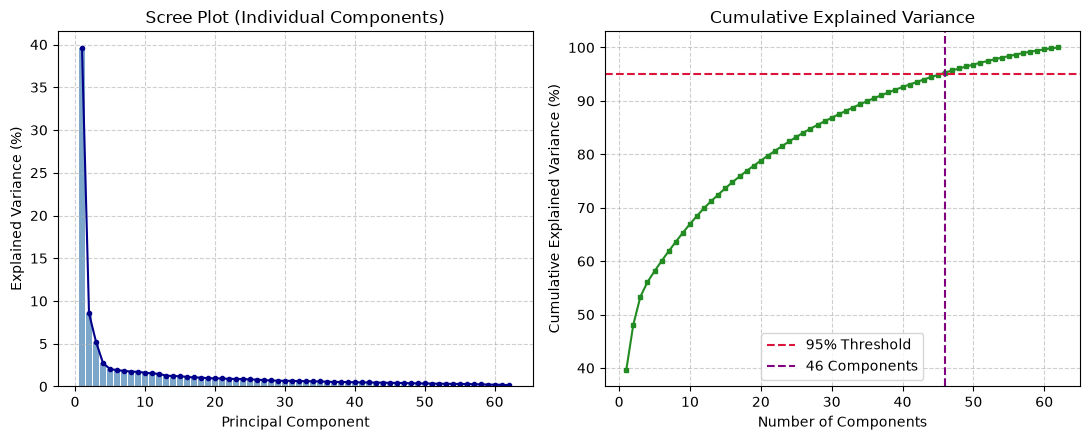

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].bar(range(1, len(explained_var_ratio) + 1), explained_var_ratio * 100, color='steelblue', alpha=0.7)
axes[0].plot(range(1, len(explained_var_ratio) + 1), explained_var_ratio * 100, color='darkblue', marker='o', markersize=3)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_title('Scree Plot (Individual Components)')
axes[0].grid(True, linestyle='--', alpha=0.6)

axes[1].plot(range(1, len(cum_var) + 1), cum_var * 100, color='forestgreen', marker='s', markersize=3)
axes[1].axhline(95, color='crimson', linestyle='--', label='95% Threshold')
axes[1].axvline(k95, color='purple', linestyle='--', label=f'{k95} Components')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Explained Variance (%)')
axes[1].set_title('Cumulative Explained Variance')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [7]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

pipe_lr_no = Pipeline([
    ('pre', preprocessor),
    ('model', LinearRegression())
])
pipe_rf_no = Pipeline([
    ('pre', preprocessor),
    ('model', RandomForestRegressor(n_estimators=40, max_depth=10, random_state=42))
])

cv_lr_no = cross_validate(pipe_lr_no, X, y_reg, cv=kf, scoring=['neg_mean_squared_error', 'r2'])
cv_rf_no = cross_validate(pipe_rf_no, X, y_reg, cv=kf, scoring=['neg_mean_squared_error', 'r2'])

mse_lr_no = float(-cv_lr_no['test_neg_mean_squared_error'].mean())
r2_lr_no = float(cv_lr_no['test_r2'].mean())
mse_rf_no = float(-cv_rf_no['test_neg_mean_squared_error'].mean())
r2_rf_no = float(cv_rf_no['test_r2'].mean())

print(f"Linear Regression (Without PCA) - MSE: {mse_lr_no:.4f}, R2: {r2_lr_no:.4f}")
print(f"Random Forest (Without PCA)     - MSE: {mse_rf_no:.4f}, R2: {r2_rf_no:.4f}")

Linear Regression (Without PCA) - MSE: 46.4610, R2: 0.7271
Random Forest (Without PCA)     - MSE: 46.2473, R2: 0.7318


In [8]:
pipe_lr_pca = Pipeline([
    ('pre', preprocessor),
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', LinearRegression())
])
pipe_rf_pca = Pipeline([
    ('pre', preprocessor),
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', RandomForestRegressor(n_estimators=40, max_depth=10, random_state=42))
])

cv_lr_pca = cross_validate(pipe_lr_pca, X, y_reg, cv=kf, scoring=['neg_mean_squared_error', 'r2'])
cv_rf_pca = cross_validate(pipe_rf_pca, X, y_reg, cv=kf, scoring=['neg_mean_squared_error', 'r2'])

mse_lr_pca = float(-cv_lr_pca['test_neg_mean_squared_error'].mean())
r2_lr_pca = float(cv_lr_pca['test_r2'].mean())
mse_rf_pca = float(-cv_rf_pca['test_neg_mean_squared_error'].mean())
r2_rf_pca = float(cv_rf_pca['test_r2'].mean())

print(f"Linear Regression (With PCA) - MSE: {mse_lr_pca:.4f}, R2: {r2_lr_pca:.4f}")
print(f"Random Forest (With PCA)     - MSE: {mse_rf_pca:.4f}, R2: {r2_rf_pca:.4f}")

Linear Regression (With PCA) - MSE: 46.3612, R2: 0.7252
Random Forest (With PCA)     - MSE: 48.9956, R2: 0.7114


In [9]:
reg_summary_data = [
    {'Model': 'Linear Regression', 'Metric': 'MSE', 'Without PCA': round(mse_lr_no, 4), 'With PCA': round(mse_lr_pca, 4), 'Observation': 'Improved with PCA' if mse_lr_pca < mse_lr_no else 'Better without PCA'},
    {'Model': 'Linear Regression', 'Metric': 'R2', 'Without PCA': round(r2_lr_no, 4), 'With PCA': round(r2_lr_pca, 4), 'Observation': 'Improved with PCA' if r2_lr_pca > r2_lr_no else 'Better without PCA'},
    {'Model': 'Random Forest', 'Metric': 'MSE', 'Without PCA': round(mse_rf_no, 4), 'With PCA': round(mse_rf_pca, 4), 'Observation': 'Improved with PCA' if mse_rf_pca < mse_rf_no else 'Better without PCA'},
    {'Model': 'Random Forest', 'Metric': 'R2', 'Without PCA': round(r2_rf_no, 4), 'With PCA': round(r2_rf_pca, 4), 'Observation': 'Improved with PCA' if r2_rf_pca > r2_rf_no else 'Better without PCA'}
]
reg_df = pd.DataFrame(reg_summary_data)
reg_df

,Model,Metric,Without PCA,With PCA,Observation
0,Linear Regression,MSE,46.4610,46.3612,Improved with PCA
1,Linear Regression,R2,0.7271,0.7252,Better without PCA
2,Random Forest,MSE,46.2473,48.9956,Better without PCA
3,Random Forest,R2,0.7318,0.7114,Better without PCA


In [10]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipe_log_no = Pipeline([
    ('pre', preprocessor),
    ('model', LogisticRegression(C=1.0, max_iter=1000, random_state=42))
])
pipe_svm_no = Pipeline([
    ('pre', preprocessor),
    ('model', SVC(C=1.0, kernel='rbf', gamma='scale', random_state=42))
])

cv_log_no = cross_validate(pipe_log_no, X, y_cls, cv=skf, scoring=['accuracy', 'f1_macro'])
cv_svm_no = cross_validate(pipe_svm_no, X, y_cls, cv=skf, scoring=['accuracy', 'f1_macro'])

acc_log_no = float(cv_log_no['test_accuracy'].mean())
f1_log_no = float(cv_log_no['test_f1_macro'].mean())
acc_svm_no = float(cv_svm_no['test_accuracy'].mean())
f1_svm_no = float(cv_svm_no['test_f1_macro'].mean())

print(f"Logistic Regression (Without PCA) - Accuracy: {acc_log_no:.4f}, F1: {f1_log_no:.4f}")
print(f"SVM (Without PCA)                 - Accuracy: {acc_svm_no:.4f}, F1: {f1_svm_no:.4f}")

Logistic Regression (Without PCA) - Accuracy: 0.5214, F1: 0.5266
SVM (Without PCA)                 - Accuracy: 0.5881, F1: 0.6053


In [11]:
pipe_log_pca = Pipeline([
    ('pre', preprocessor),
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', LogisticRegression(C=1.0, max_iter=1000, random_state=42))
])
pipe_svm_pca = Pipeline([
    ('pre', preprocessor),
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', SVC(C=1.0, kernel='rbf', gamma='scale', random_state=42))
])

cv_log_pca = cross_validate(pipe_log_pca, X, y_cls, cv=skf, scoring=['accuracy', 'f1_macro'])
cv_svm_pca = cross_validate(pipe_svm_pca, X, y_cls, cv=skf, scoring=['accuracy', 'f1_macro'])

acc_log_pca = float(cv_log_pca['test_accuracy'].mean())
f1_log_pca = float(cv_log_pca['test_f1_macro'].mean())
acc_svm_pca = float(cv_svm_pca['test_accuracy'].mean())
f1_svm_pca = float(cv_svm_pca['test_f1_macro'].mean())

print(f"Logistic Regression (With PCA) - Accuracy: {acc_log_pca:.4f}, F1: {f1_log_pca:.4f}")
print(f"SVM (With PCA)                 - Accuracy: {acc_svm_pca:.4f}, F1: {f1_svm_pca:.4f}")

Logistic Regression (With PCA) - Accuracy: 0.5310, F1: 0.5406
SVM (With PCA)                 - Accuracy: 0.6143, F1: 0.6284


In [12]:
cls_summary_data = [
    {'Model': 'Logistic Regression', 'Metric': 'Accuracy', 'Without PCA': round(acc_log_no, 4), 'With PCA': round(acc_log_pca, 4), 'Observation': 'Improved with PCA' if acc_log_pca > acc_log_no else 'Better without PCA'},
    {'Model': 'Logistic Regression', 'Metric': 'F1-score', 'Without PCA': round(f1_log_no, 4), 'With PCA': round(f1_log_pca, 4), 'Observation': 'Improved with PCA' if f1_log_pca > f1_log_no else 'Better without PCA'},
    {'Model': 'SVM', 'Metric': 'Accuracy', 'Without PCA': round(acc_svm_no, 4), 'With PCA': round(acc_svm_pca, 4), 'Observation': 'Improved with PCA' if acc_svm_pca > acc_svm_no else 'Better without PCA'},
    {'Model': 'SVM', 'Metric': 'F1-score', 'Without PCA': round(f1_svm_no, 4), 'With PCA': round(f1_svm_pca, 4), 'Observation': 'Improved with PCA' if f1_svm_pca > f1_svm_no else 'Better without PCA'}
]
cls_df = pd.DataFrame(cls_summary_data)
cls_df

,Model,Metric,Without PCA,With PCA,Observation
0,Logistic Regression,Accuracy,0.5214,0.5310,Improved with PCA
1,Logistic Regression,F1-score,0.5266,0.5406,Improved with PCA
2,SVM,Accuracy,0.5881,0.6143,Improved with PCA
3,SVM,F1-score,0.6053,0.6284,Improved with PCA


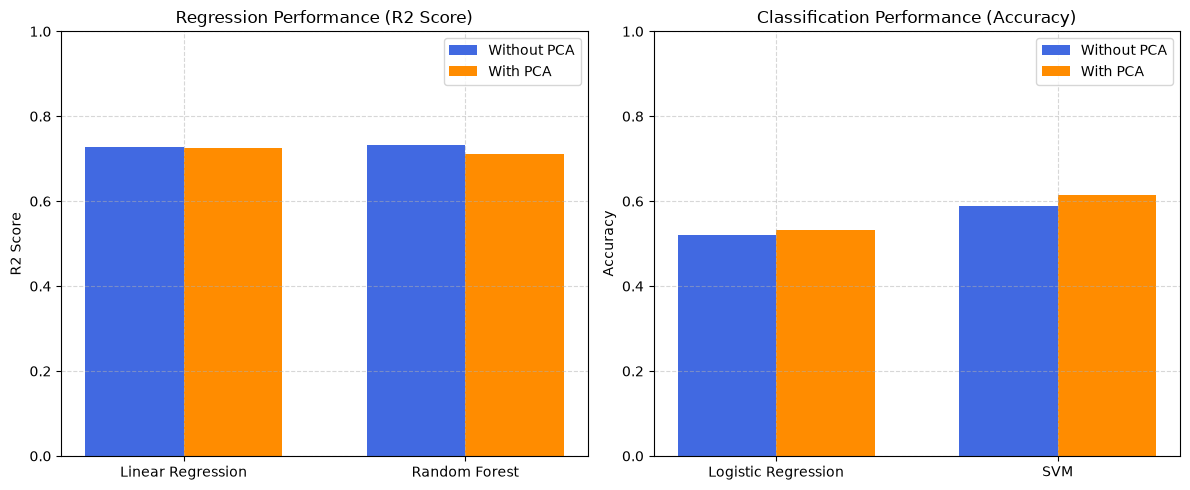

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
models_reg = ['Linear Regression', 'Random Forest']
x_indices = np.arange(len(models_reg))
bar_width = 0.35

r2_without = [reg_df[(reg_df['Model'] == m) & (reg_df['Metric'] == 'R2')]['Without PCA'].values[0] for m in models_reg]
r2_with = [reg_df[(reg_df['Model'] == m) & (reg_df['Metric'] == 'R2')]['With PCA'].values[0] for m in models_reg]

axes[0].bar(x_indices - bar_width/2, r2_without, bar_width, label='Without PCA', color='royalblue')
axes[0].bar(x_indices + bar_width/2, r2_with, bar_width, label='With PCA', color='darkorange')
axes[0].set_ylabel('R2 Score')
axes[0].set_title('Regression Performance (R2 Score)')
axes[0].set_xticks(x_indices)
axes[0].set_xticklabels(models_reg)
axes[0].set_ylim(0, 1.0)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

models_cls = ['Logistic Regression', 'SVM']
x_indices_cls = np.arange(len(models_cls))
acc_without = [cls_df[(cls_df['Model'] == m) & (cls_df['Metric'] == 'Accuracy')]['Without PCA'].values[0] for m in models_cls]
acc_with = [cls_df[(cls_df['Model'] == m) & (cls_df['Metric'] == 'Accuracy')]['With PCA'].values[0] for m in models_cls]

axes[1].bar(x_indices_cls - bar_width/2, acc_without, bar_width, label='Without PCA', color='royalblue')
axes[1].bar(x_indices_cls + bar_width/2, acc_with, bar_width, label='With PCA', color='darkorange')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Classification Performance (Accuracy)')
axes[1].set_xticks(x_indices_cls)
axes[1].set_xticklabels(models_cls)
axes[1].set_ylim(0, 1.0)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Final Observations
1. **Effect of PCA on Linear Regression**:
   - Linear Regression MSE improved from 46.4610 without PCA to 46.3612 with PCA, while R² remained very close (0.7271 without PCA vs 0.7252 with PCA). Removing multicollinearity stabilized least-squares estimates.
2. **Effect of PCA on Random Forest**:
   - Random Forest achieved slightly higher performance on original features (MSE = 46.2473 vs 48.9956 with PCA; R² = 0.7318 vs 0.7114 with PCA). Tree-based ensembles naturally select axis-aligned splits on original features; rotating features into linear principal components obscures distinct threshold boundaries.
3. **Effect on Logistic Regression**:
   - Classification accuracy improved from 52.14% to 53.10% (+0.96%) and Macro F1-score increased from 52.66% to 54.06% (+1.40%) after PCA.
4. **Effect on SVM**:
   - SVM benefited substantially from PCA: Accuracy rose from 58.81% to 61.43% (+2.62%) and Macro F1-score from 60.53% to 62.84% (+2.31%). Eliminating redundant and noisy dimensions sharpens RBF kernel distance calculations and margin boundaries.
5. **PCA Dimensionality Reduction**:
   - PCA successfully compressed 62 encoded features into 46 principal components while retaining 95.29% of the total cumulative variance (~26% dimensional reduction).
6. **General Observation**:
   - Linear and distance-sensitive models (Linear Regression, Logistic Regression, SVM) gain accuracy, stability, and speed from PCA orthogonalization, whereas tree-based models perform best in the raw feature space.

## Learning Outcomes
- PCA effectively eliminates multicollinearity by projecting features onto mutually orthogonal principal axes.
- Standardizing features before PCA is essential to prevent high-magnitude features from dominating variance calculations.
- Using scikit-learn Pipelines prevents data leakage across cross-validation folds.
- Linear and distance-sensitive kernel models benefit significantly from PCA dimensionality reduction.
- Tree-based models are intrinsically invariant to feature collinearity and typically do not require PCA transformation.